<a href="https://colab.research.google.com/github/CrisDev96/Proyecto-Programacion-RN-Grupo3/blob/main/07MIAR_Proyecto_Programacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 07MIAR - Redes Neuronales y Deep Learning: Proyecto de programación "*Deep Vision in classification tasks*"


## Enunciado

En esta actividad, el alumno debe **evaluar y comparar dos estrategias** para la **clasificación de imágenes** empleando el **dataset asignado**. El/La alumnx deberá resolver el reto proponiendo una solución válida **basada en aprendizaje profundo**, más concretamente en redes neuronales convolucionales (**CNNs**). Será indispensable que la solución propuesta siga el **pipeline visto en clase** para resolver este tipo de tareas de inteligencia artificial:

1.   **Carga** del conjunto de datos
2.   **Inspección** del conjunto de datos
3.   **Acondicionamiento** del conjunto de datos
4.   Desarrollo de la **arquitectura** de red neuronal y **entrenamiento** de la solución
5.   **Monitorización** del proceso de **entrenamiento** para la toma de decisiones
6.   **Evaluación** del modelo predictivo y planteamiento de la siguiente prueba experimental

### Estrategia 1: Entrenar desde cero o *from scratch*

La primera estrategia a comparar será una **red neuronal profunda** que el **alumno debe diseñar, entrenar y optimizar**. Se debe **justificar empíricamente** las decisiones que llevaron a la selección de la **arquitectura e hiperparámetros final**. Se espera que el alumno utilice todas las **técnicas de regularización** mostradas en clase de forma justificada para la mejora del rendimiento de la red neuronal (*weight regularization*, *dropout*, *batch normalization*, *data augmentation*, etc.).

### Estrategia 2: Red pre-entrenada

La segunda estrategia a comparar debe incluir la utilización de una **red preentrenada** con el dataset ImageNet, llevando a cabo tareas de ***transfer learning*** y ***fine-tuning*** para resolver la tarea de clasificación asignada. Deben **compararse al menos dos tipos de arquitecturas** (VGGs, ResNet50, Xception, InceptionV3, InceptionResNetV2, MobileNetV2, DenseNet, ResNet) y se debe **seleccionar la que mayor precisión proporcione** (información sobre las arquitecturas disponibles en https://keras.io/applications/). Se espera que el/la alumnx utilice todas las **técnicas de regularización** mostradas en clase de forma justificada para la mejora del rendimiento de la red neuronal (*weight regularization*, *dropout*, *batch normalization*, *data augmentation*, etc.).

## Normas a seguir

- Será **indispensable** realizar el **trabajo por parejas**. Dichas parejas de alumnxs se generarán **de manera automática** teniendo en cuenta el pais de residencia con el objetivo de facilitar el trabajo en equipo.  
- Se debe entregar un **ÚNICO FICHERO PDF POR ALUMNO** que incluya las instrucciones presentes en el Colab Noteboook y su **EJECUCIÓN!!!**. Debe aparecer todo el proceso llevado a cabo en cada estrategia (i.e. carga de datos, inspección de datos, acondicionamiento, proceso de entrenamiento y proceso de validación del modelo).
- **La memoria del trabajo** (el fichero PDF mencionado en el punto anterior) deberá **subirla cada integrante del grupo** (aunque se trate de un documento idéntico) a la actividad que se habilitará **en CampusVIU**.
- Se recomienda trabajar respecto a un directorio base (**BASE_FOLDER**) para facilitar el trabajo en equipo. En este notebook se incluye un ejemplo de cómo almacenar/cargar datos utilizando un directorio base.
- Las **redes propuestas** deben estar **entrenadas** (y **EVIDENCIAR este proceso en el documento PDF**). La entrega de una **red sin entrenar** supondrá **perdida de puntos**.
- Si se desea **evidenciar alguna métrica** del proceso de entrenamiento (precisión, pérdida, etc.), estas deben ser generadas.
- Todos los **gráficos** que se deseen mostrar deberán **generarse en el Colab Notebook** para que tras la conversión aparezcan en el documento PDF.

## *Tips* para realizar la actividad con éxito
- Los **datos** se cargarán directamente **desde** la plataforma **Kaggle** mediante su API (https://github.com/Kaggle/kaggle-api). En este Notebook se incluye un ejemplo de como hacerlo. Se recomienda generar una función que aborde esta tarea.
- El **documento PDF a entregar** como solución de la actividad se debe **generar automáticamente desde el fichero ".ipynb"**. En este Notebook se incluye un ejemplo de como hacerlo.
- **Generar secciones y subsecciones en el Colab Notebook** supondrá que el documento **PDF generado** queda totalmente **ordenado** facilitando la evaluación al docente.
- Se recomienda encarecidamente **incluir comentarios concisos pero aclaratorios**.
- Es muy recomendable crear una **última sección** de texto en el Colab Notebook en la que se discutan los diferentes modelos obtenidos y se extraigan las conclusiones pertinentes.

## Criterios de evaluación

- **Seguimiento** de las **normas establecidas** en la actividad (detalladas anteriormente).
- Creación de una **solución que resuelva la tarea de clasificación**, i.e. que las figuras de mérito empleadas para medir la bondad del modelo predictivo evidencien un *performance* superior al rendimiento estocástico.
- **Claridad** en la creación de la solución, en las justificaciones sobre la toma de decisiones llevada a cabo así como en las comparativas y conclusiones finales.
- **Efectividad** al presentar las comparaciones entre métricas de evaluación de ambas estrategias.
- **Demostración** de la utilización de **técnicas de regularización** para mejorar el rendimiento de los modelos.

In [1]:
#Librerias

import kagglehub
import os
import matplotlib.pyplot as plt
from PIL import Image
import random
import numpy as np
import pandas as pd
import tensorflow as tf
from pathlib import Path
from sklearn.model_selection import train_test_split

## Cargando datos del dataset de la plataforma Kaggle

In [2]:
# Descarga del dataset basandonos en Keagglehub
path = kagglehub.dataset_download("hasibalmuzdadid/shoe-vs-sandal-vs-boot-dataset-15k-images")

print("Path to dataset files:", path)

100%|██████████| 47.0M/47.0M [00:04<00:00, 12.1MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/hasibalmuzdadid/shoe-vs-sandal-vs-boot-dataset-15k-images/versions/2


In [3]:
#Mostrar contenido del dataset

for elemento in os.listdir(path):
    ruta = os.path.join(path, elemento)

    if os.path.isdir(ruta):
        print(f"Carpeta: {elemento}")
        print("Subcarpetas:", os.listdir(ruta))
    else:
        print(f"Archivo: {elemento}")

Carpeta: Shoe vs Sandal vs Boot Dataset
Subcarpetas: ['Sandal', 'Boot', 'Shoe']


In [4]:
# Buscar las carpetas de las clases
for root, dirs, files in os.walk(path):
    if files:
        imagenes = [
            f for f in files
            if f.lower().endswith(('.jpg', '.jpeg', '.png'))
        ]

        if imagenes:
            print(f"Carpeta: {root}")
            print(f"Cantidad de imágenes: {len(imagenes)}")
            print("-" * 40)

Carpeta: /root/.cache/kagglehub/datasets/hasibalmuzdadid/shoe-vs-sandal-vs-boot-dataset-15k-images/versions/2/Shoe vs Sandal vs Boot Dataset/Sandal
Cantidad de imágenes: 5000
----------------------------------------
Carpeta: /root/.cache/kagglehub/datasets/hasibalmuzdadid/shoe-vs-sandal-vs-boot-dataset-15k-images/versions/2/Shoe vs Sandal vs Boot Dataset/Boot
Cantidad de imágenes: 5000
----------------------------------------
Carpeta: /root/.cache/kagglehub/datasets/hasibalmuzdadid/shoe-vs-sandal-vs-boot-dataset-15k-images/versions/2/Shoe vs Sandal vs Boot Dataset/Shoe
Cantidad de imágenes: 5000
----------------------------------------


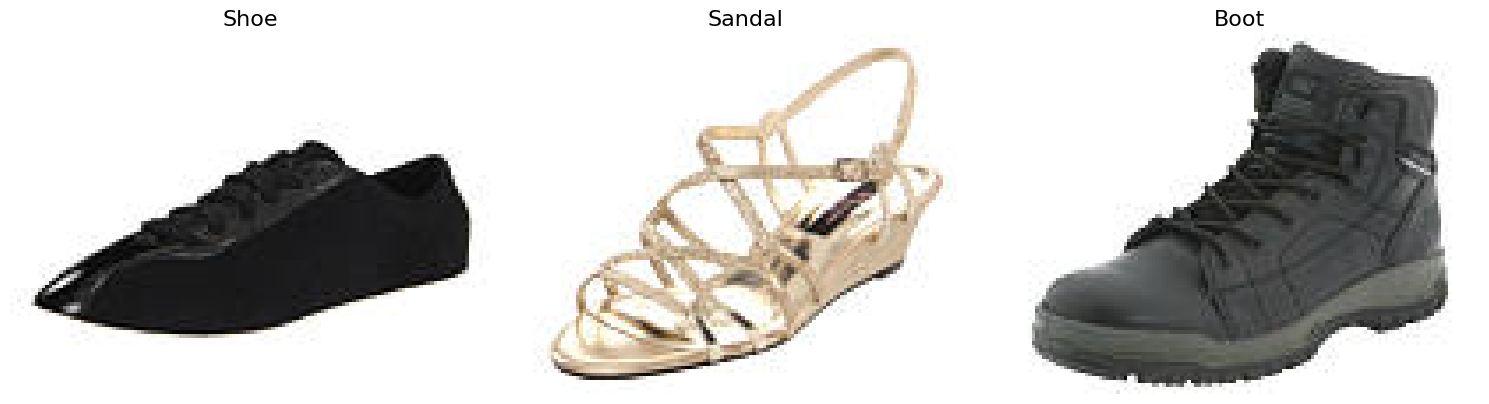

In [5]:
dataset_path = path

# Buscar las imágenes de cada clase
clases = ['Shoe', 'Sandal', 'Boot']

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for i, clase in enumerate(clases):

    # Buscar la carpeta correspondiente a la clase
    carpeta_clase = None

    for root, dirs, files in os.walk(dataset_path):
        if os.path.basename(root).lower() == clase.lower():
            carpeta_clase = root
            break

    # Obtener las imágenes
    imagenes = [
        f for f in os.listdir(carpeta_clase)
        if f.lower().endswith(('.jpg', '.jpeg', '.png'))
    ]

    # Seleccionar una imagen aleatoria
    imagen_seleccionada = random.choice(imagenes)

    # Abrir imagen
    ruta_imagen = os.path.join(carpeta_clase, imagen_seleccionada)
    imagen = Image.open(ruta_imagen)

    # Mostrar imagen
    axes[i].imshow(imagen)
    axes[i].set_title(clase, fontsize=16)
    axes[i].axis('off')

plt.tight_layout()
plt.show()

# Acondicionamineto de Datos del DataSet

El objetivo del acondicionamiento es preparar las imágenes para que posteriormente podamos entrenar un modelo de Machine Learning o Deep Learning.

In [6]:

# Diccionario de clases y etiquetas
clases_a_etiquetas = {
    'Shoe': 0,
    'Sandal': 1,
    'Boot': 2
}

# Listas para almacenar las rutas y etiquetas
image_paths = []
image_labels = []

# Recorrer las clases
for clase in clases:

    # Buscar la carpeta correspondiente
    carpeta_clase = None

    for root, dirs, files in os.walk(dataset_path):
        if os.path.basename(root).lower() == clase.lower():
            carpeta_clase = root
            break

    # Recorrer las imágenes de la carpeta
    for archivo in sorted(os.listdir(carpeta_clase)):

        if archivo.lower().endswith(('.jpg', '.jpeg', '.png')):

            image_paths.append(
                os.path.join(carpeta_clase, archivo)
            )

            image_labels.append(clases_a_etiquetas[clase])

# Convertir a arrays de NumPy
image_paths = np.array(image_paths)
image_labels = np.array(image_labels)

print("Total de imágenes:", len(image_paths))
print("Total de etiquetas:", len(image_labels))

Total de imágenes: 15000
Total de etiquetas: 15000


## División de conjunto de datos

In [7]:
# Primera división: 70% entrenamiento y 30% temporal
X_train, X_temp, y_train, y_temp = train_test_split(
    image_paths,
    image_labels,
    test_size=0.30,
    random_state=42,
    stratify=image_labels
)

# Segunda división: 15% validación y 15% pruebas
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Imágenes de entrenamiento:", len(X_train))
print("Imágenes de validación:", len(X_val))
print("Imágenes de prueba:", len(X_test))

Imágenes de entrenamiento: 10500
Imágenes de validación: 2250
Imágenes de prueba: 2250


## Normalización de imagenes

In [8]:
# Tamaño de las imágenes
IMG_SIZE = (150, 150)

def preprocesar_imagen(image_path, label):

    # Leer imagen
    imagen = tf.io.read_file(image_path)

    # Convertir a RGB
    imagen = tf.io.decode_image(
        imagen,
        channels=3,
        expand_animations=False
    )

    imagen.set_shape([None, None, 3])

    # Redimensionar
    imagen = tf.image.resize(imagen, IMG_SIZE)

    # Normalizar
    imagen = imagen / 255.0

    return imagen, label


In [9]:
# Tamaño de los lotes
BATCH_SIZE = 32

# Función para crear los datasets
def crear_dataset(paths, labels, entrenamiento=False):

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if entrenamiento:
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=42
        )

    dataset = dataset.map(
        preprocesar_imagen,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


# Crear los tres conjuntos
train_dataset = crear_dataset(X_train, y_train, entrenamiento=True)
val_dataset = crear_dataset(X_val, y_val)
test_dataset = crear_dataset(X_test, y_test)

print("Conjunto de datos creaado")

Conjunto de datos creaado


## Revisar conjunto de datos despúes del acondicionamiento

In [10]:
# Obtener un lote de entrenamiento
imagenes, etiquetas = next(iter(train_dataset))

print("Dimensiones del lote:", imagenes.shape)
print("Tipo de datos:", imagenes.dtype)
print("Valor mínimo:", tf.reduce_min(imagenes).numpy())
print("Valor máximo:", tf.reduce_max(imagenes).numpy())

Dimensiones del lote: (32, 150, 150, 3)
Tipo de datos: <dtype: 'float32'>
Valor mínimo: 0.0
Valor máximo: 1.0


Este resultado representa el batch size 32, las dos dimensiones de las imagenes alto y ancho 150 pixeles, y 3 que representa la escala RGB.

## Data augmentetion

En esta sección vamos a variar las imagenes del dataset modificando un poco su horientacion y rotarlas un poco para que la red neuronal pueda identificar el calzado mas eficiente.

In [11]:
# Data Augmentation
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomTranslation(
        height_factor=0.10,
        width_factor=0.10
    ),
    tf.keras.layers.RandomZoom(0.10)
], name="data_augmentation")

print("Data Augmentation creado correctamente")


Data Augmentation creado correctamente


Ahora vamos a tomar una imagen de nuestro conjunto de entrenamiento y generar varias versiones transformadas.

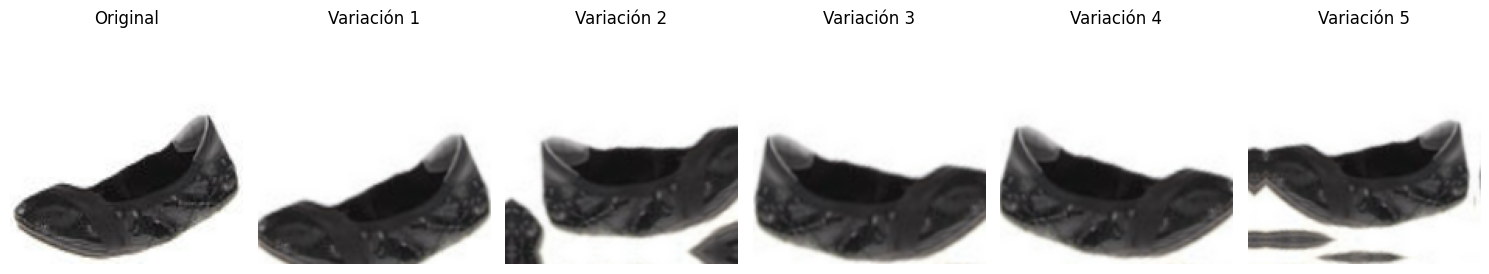

In [12]:

# Obtener una imagen del conjunto de entrenamiento
imagenes, etiquetas = next(iter(train_dataset))

imagen_original = imagenes[0]

# Generar 5 variaciones
plt.figure(figsize=(15, 3))

# Imagen original
plt.subplot(1, 6, 1)
plt.imshow(imagen_original.numpy())
plt.title("Original")
plt.axis("off")

# Variaciones
for i in range(5):

    imagen_transformada = data_augmentation(
        tf.expand_dims(imagen_original, axis=0),
        training=True
    )[0]

    plt.subplot(1, 6, i + 2)
    plt.imshow(imagen_transformada.numpy())
    plt.title(f"Variación {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

Utilizamos Data Augmentation por medio de transformación aleatoria a las capas utilizando TensorFlow Keras, lo cual nos permite generar variaciones de las imágenes durante el entrenamiento mediante operaciones de volteo horizontal, rotación, traslación y zoom.


# Estrategia 1: Entrenar desde cero o *from scratch*

En esta estrategia vamos a crear redes neuronales profundas para identificar el tipo de calzado que se muestra en las imagenes. En este caso vamos a aplicar las técnicas de regularización mostradas en clase.

# 1. CNN tipo VGG

A continuación vamos a implementar una red neuronal convolucional (CNN) basada en la arquitectura VGG, incorporando técnicas de regularización para mejorar la capacidad de generalización del modelo.

La arquitectura VGG se caracteriza por utilizar bloques convolucionales consecutivos, generalmente con filtros de tamaño 3 × 3, seguidos de operaciones de reducción dimensional (Max Pooling).

La arquitectura propuesta, inspirada en VGG, recibe imágenes RGB de $150 \times 150 \times 3$ y extrae características progresivas mediante tres bloques convolucionales; cada bloque combina dos capas Conv2D de $3 \times 3$ (con 32, 64 y 128 filtros respectivamente), Batch Normalization, activación ReLU y un MaxPooling de $2 \times 2$. Posteriormente, la etapa de clasificación aplica GlobalAveragePooling2D, una capa densa de 256 neuronas con ReLU, Batch Normalization, Dropout del 0.5 y una capa final de salida con 3 neuronas y Softmax para clasificar las imágenes en Shoe, Sandal o Boot.

La idea de VGG es extraer progresivamente características visuales. Las primeras capas identifican elementos simples, como bordes y texturas; las capas posteriores combinan estas características para identificar patrones más complejos que permitan diferenciar zapatos, sandalias y botas.

#Definir parametros de la aruitectura

In [ ]:
# Intensidad de regularización L2
L2_VALUE = 0.00001
NUM_CLASES = 3

print("Tamaño de entrada:", IMG_SIZE)
print("Cantidad de clases:", NUM_CLASES)
print("Regularización L2:", L2_VALUE)

Tamaño de entrada: (150, 150)
Cantidad de clases: 3
Regularización L2: 1e-05


#Bloque de Convoluciones

In [ ]:
def bloque_vgg(x, filtros):

    # Primera convolución
    x = tf.keras.layers.Conv2D(
        filtros,
        kernel_size=(3, 3),
        padding='same',
        kernel_regularizer=tf.keras.regularizers.l2(L2_VALUE)
    )(x)

    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)

    # Segunda convolución
    x = tf.keras.layers.Conv2D(
        filtros,
        kernel_size=(3, 3),
        padding='same',
        kernel_regularizer=tf.keras.regularizers.l2(L2_VALUE)
    )(x)

    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation('relu')(x)

    # Reducción espacial
    x = tf.keras.layers.MaxPooling2D(
        pool_size=(2, 2)
    )(x)

    return x

Nuestra red estará compuesta por tres bloques convolucionales y un clasificador final.

- Bloque 1 (32):	2 convoluciones + BN + ReLU + MaxPooling
- Bloque 2 (64):	2 convoluciones + BN + ReLU + MaxPooling
- Bloque 3 (128):	2 convoluciones + BN + ReLU + MaxPooling
- Clasificador	(256):	Dense + BN + Dropout
- Salida:	(3)	Softmax

#Construcción del modelo

In [ ]:
# Entrada de las imágenes
entrada = tf.keras.layers.Input(
    shape=(150, 150, 3),
    name="entrada_imagen"
)

# Data Augmentation
x = data_augmentation(entrada)

# Bloque convolucional 1: 32 filtros
x = bloque_vgg(x, 32)

# Bloque convolucional 2: 64 filtros
x = bloque_vgg(x, 64)

# Bloque convolucional 3: 128 filtros
x = bloque_vgg(x, 128)

# Clasificador
x = tf.keras.layers.GlobalAveragePooling2D()(x)

x = tf.keras.layers.Dense(
    256,
    kernel_regularizer=tf.keras.regularizers.l2(L2_VALUE)
)(x)

x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.Activation('relu')(x)

# Dropout
x = tf.keras.layers.Dropout(0.5)(x)

# Capa de salida: 3 clases
salida = tf.keras.layers.Dense(
    NUM_CLASES,
    activation='softmax',
    name="clasificacion"
)(x)

# Crear modelo
model = tf.keras.Model(
    inputs=entrada,
    outputs=salida,
    name="CNN_VGG_Shoe_Sandal_Boot"
)

print("Modelo construido correctamente")


Modelo construido correctamente


La idea de VGG es extraer progresivamente características visuales. Las primeras capas identifican elementos simples, como bordes y texturas; las capas posteriores combinan estas características para identificar patrones más complejos que permitan diferenciar zapatos, sandalias y botas.

In [ ]:
# Resumen de la arquitectura
model.summary()

Model: "CNN_VGG_Shoe_Sandal_Boot"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ entrada_imagen (InputLayer)     │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 150, 150, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 150, 150, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 150, 150, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 150, 150, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 150, 150, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 75, 75, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 75, 75, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 75, 75, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 37, 37, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 37, 37, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 37, 37, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 37, 37, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_5 (Activation)       │ (None, 37, 37, 128)    │             

 Total params: 323,619 (1.23 MB)

 Trainable params: 322,211 (1.23 MB)

 Non-trainable params: 1,408 (5.50 KB)

#Compilación del Modelo

In [ ]:
# Compilación del modelo

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("Modelo compilado correctamente")

Modelo compilado correctamente


In [ ]:
# Callbacks

callbacks = [

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss',
        factor=0.5,
        patience=2,
        min_lr=0.00001,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath='/kaggle/working/mejor_modelo.keras',
        monitor='val_loss',
        save_best_only=True,
        verbose=1
    )
]

print("Callbacks configurados correctamente")

Callbacks configurados correctamente


Configuramos un optimizador Adam, para ajustar los pesos de la red, así mismo implementamos una función de pérdida Sparse Categorical Crossentropy, porque nuestras etiquetas son números enteros 0 (Shoe), 1 (Sandal) y 2 (Boots) y utilizamos el Accuracy para medir qué porcentaje de imágenes clasifica correctamente.

# Entrenamiento

In [ ]:
# Entrenamiento

EPOCHS = 50

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS,
    callbacks=callbacks
)

Epoch 1/50
329/329 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step - accuracy: 0.6296 - loss: 0.8953
Epoch 1: val_loss improved from None to 3.99336, saving model to /kaggle/working/mejor_modelo.keras

Epoch 1: finished saving model to /kaggle/working/mejor_modelo.keras
329/329 ━━━━━━━━━━━━━━━━━━━━ 62s 147ms/step - accuracy: 0.6966 - loss: 0.7369 - val_accuracy: 0.3462 - val_loss: 3.9934 - learning_rate: 0.0010
Epoch 2/50
328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - accuracy: 0.7996 - loss: 0.4996
Epoch 2: val_loss did not improve from 3.99336
329/329 ━━━━━━━━━━━━━━━━━━━━ 44s 133ms/step - accuracy: 0.8087 - loss: 0.4798 - val_accuracy: 0.3573 - val_loss: 6.5345 - learning_rate: 0.0010
Epoch 3/50
328/329 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step - accuracy: 0.8384 - loss: 0.4218
Epoch 3: val_loss improved from 3.99336 to 1.42891, saving model to /kaggle/working/mejor_modelo.keras

Epoch 3: finished saving model to /kaggle/working/mejor_modelo.keras
329/329 ━━━━━━━━━━━━━━━━━━━━ 48s 145ms/step - accuracy: 0.

Al inicio se planteo 30 epocas y un learning rate 0.001, sin embargo, al tener un laerning rate tan alto el modelo estaba presentando sobre ajuste, el cual estaba notandose no mas en la epoca 2. Por ende se incremento las epocas ha 50 y se utilizó ub learning rate de 0.00001, mejorando considerablemente el modelo, permitiendo que el modelo haga ajustes mas graduales a los pesos de las redes.

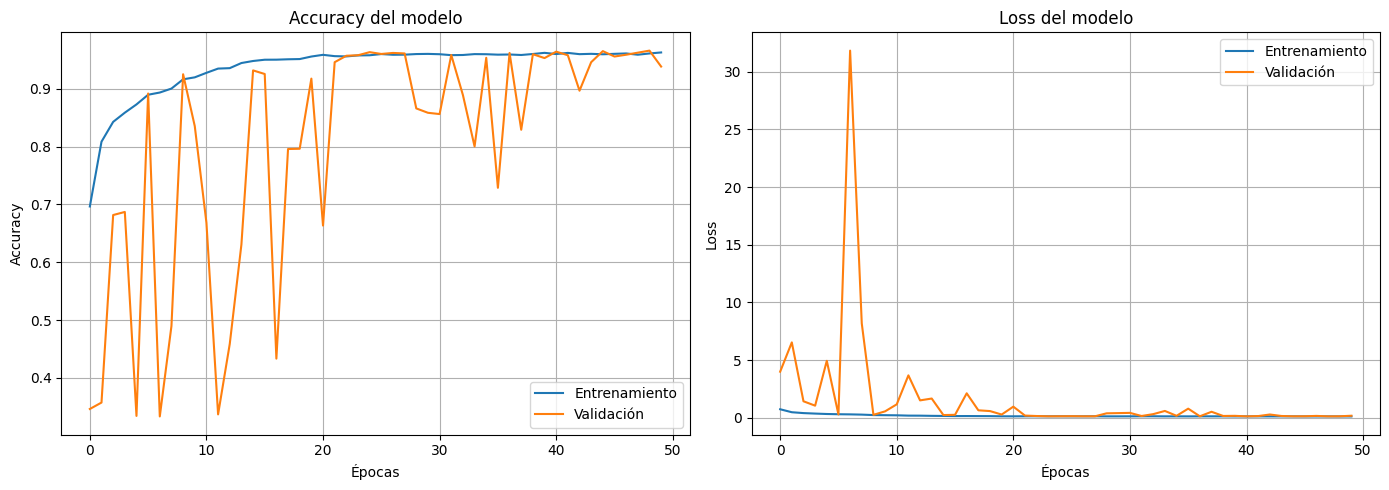

In [ ]:
# Visualización del entrenamiento

plt.figure(figsize=(14, 5))

# Gráfica de accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Entrenamiento')
plt.plot(history.history['val_accuracy'], label='Validación')
plt.title('Accuracy del modelo')
plt.xlabel('Épocas')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Gráfica de loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Entrenamiento')
plt.plot(history.history['val_loss'], label='Validación')
plt.title('Loss del modelo')
plt.xlabel('Épocas')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Evaluando el modelo

In [ ]:
# Cargar el mejor modelo del último entrenamiento

mejor_modelo = tf.keras.models.load_model(
    '/kaggle/working/mejor_modelo.keras'
)

print("Modelo cargado correctamente")

Modelo cargado correctamente


In [ ]:
# Evaluación con el conjunto de prueba

test_loss, test_accuracy = mejor_modelo.evaluate(test_dataset)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

71/71 ━━━━━━━━━━━━━━━━━━━━ 13s 127ms/step - accuracy: 0.9671 - loss: 0.1170
Test Loss: 0.1170
Test Accuracy: 96.71%


71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step


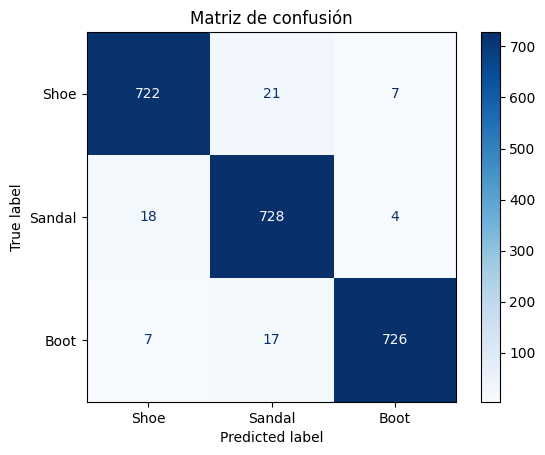

              precision    recall  f1-score   support

        Shoe       0.97      0.96      0.96       750
      Sandal       0.95      0.97      0.96       750
        Boot       0.99      0.97      0.98       750

    accuracy                           0.97      2250
   macro avg       0.97      0.97      0.97      2250
weighted avg       0.97      0.97      0.97      2250



In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Etiquetas reales
y_real = np.concatenate([
    etiquetas.numpy()
    for imagenes, etiquetas in test_dataset
])

# Predicciones
predicciones = mejor_modelo.predict(test_dataset)

y_pred = np.argmax(predicciones, axis=1)

# Matriz de confusión
matriz = confusion_matrix(y_real, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=['Shoe', 'Sandal', 'Boot']
)

disp.plot(cmap='Blues', values_format='d')
plt.title('Matriz de confusión')
plt.show()

# Reporte de clasificación
print(classification_report(
    y_real,
    y_pred,
    target_names=['Shoe', 'Sandal', 'Boot']
))

Como podemos ver de las 2.250 imágenes de prueba, el modelo clasificó correctamente aproximadamente 2.176 y se equivocó en aproximadamente 74. Asi mismo, la confusión más frecuente se produce entre Shoe y Sandal. Siendo Boot el mas acertivo de la red neuronal, con un 98% de acertación.

In [ ]:
# Obtener predicciones del modelo
predicciones = mejor_modelo.predict(test_dataset)

# Obtener la clase predicha
clases_predichas = np.argmax(predicciones, axis=1)

# Obtener la confianza de cada predicción
confianzas = np.max(predicciones, axis=1)

# Obtener las etiquetas reales
etiquetas_reales = np.concatenate([
    etiquetas.numpy()
    for imagenes, etiquetas in test_dataset
])

print("Predicciones generadas correctamente")

71/71 ━━━━━━━━━━━━━━━━━━━━ 3s 39ms/step
Predicciones generadas correctamente


In [ ]:
# Reunir todas las imágenes del conjunto de prueba

imagenes_test = np.concatenate([
    imagenes.numpy()
    for imagenes, etiquetas in test_dataset
], axis=0)

print("Imágenes de prueba:", imagenes_test.shape)

Imágenes de prueba: (2250, 150, 150, 3)


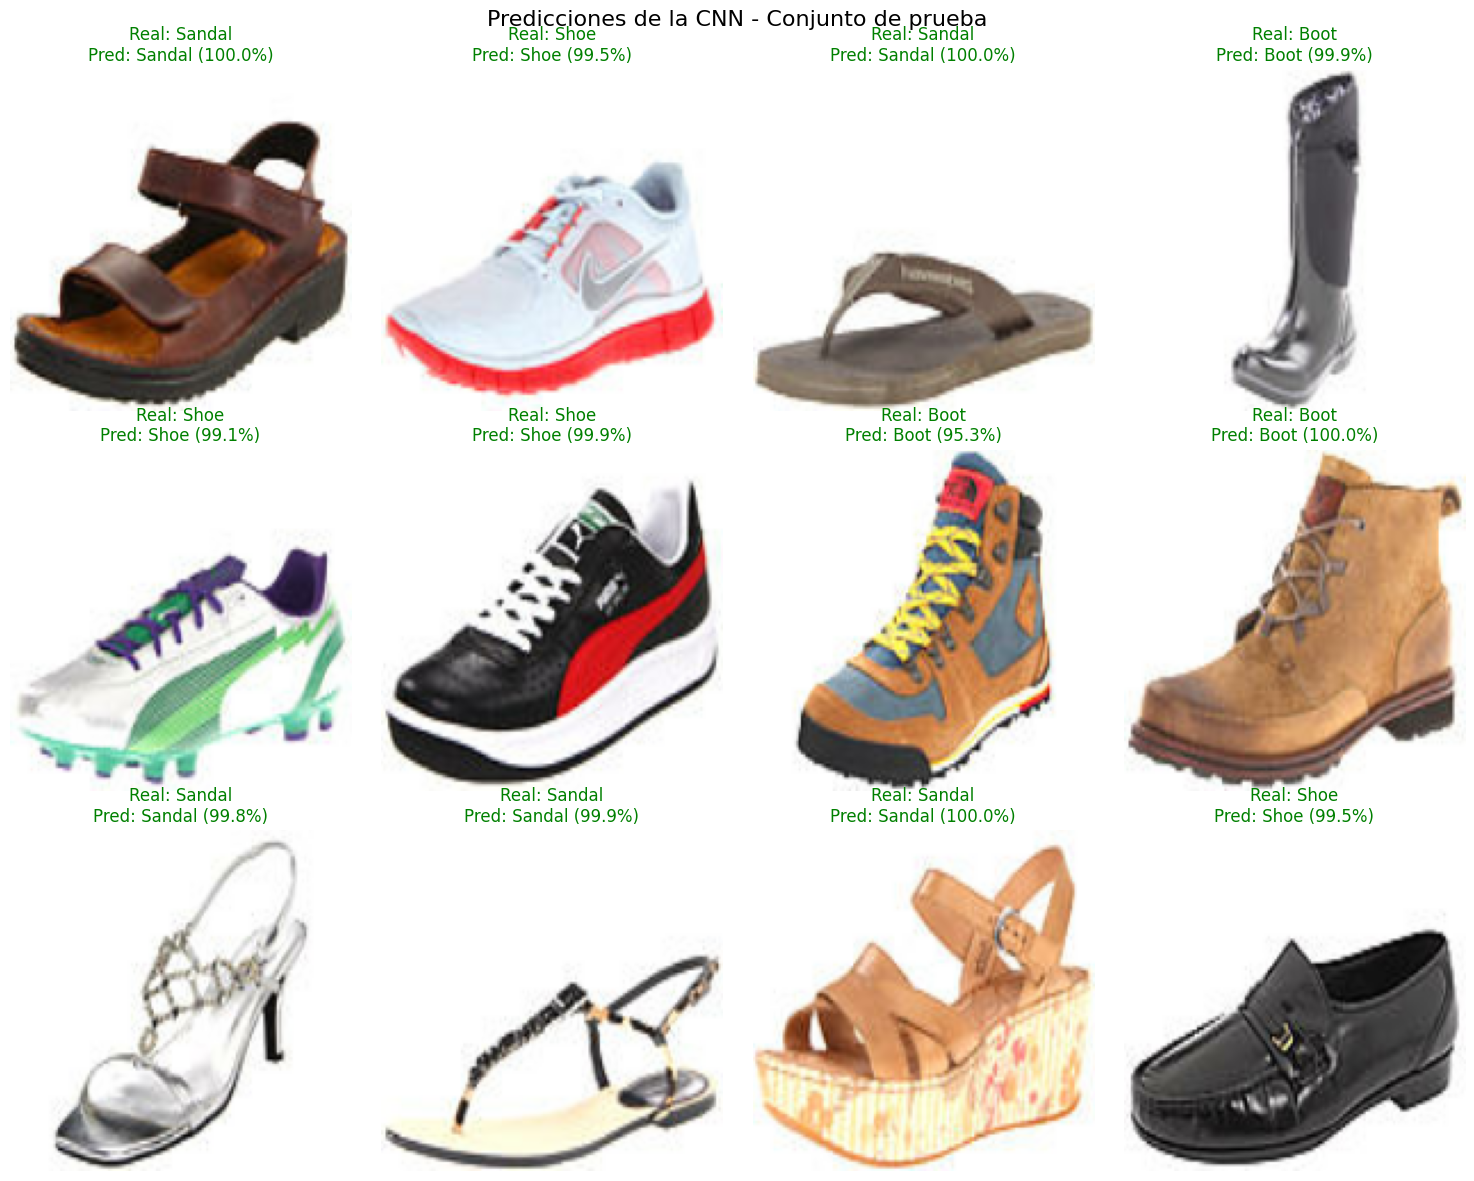

In [ ]:
# Visualización final de predicciones

NUM_IMAGENES = 12

indices = np.random.choice(
    len(imagenes_test),
    size=NUM_IMAGENES,
    replace=False
)

plt.figure(figsize=(15, 12))

for i, indice in enumerate(indices):

    plt.subplot(3, 4, i + 1)

    # Mostrar imagen
    plt.imshow(imagenes_test[indice])

    # Obtener etiquetas
    clase_real = clases[etiquetas_reales[indice]]
    clase_predicha = clases[clases_predichas[indice]]

    # Confianza
    confianza = confianzas[indice] * 100

    # Verificar si la predicción es correcta
    correcta = etiquetas_reales[indice] == clases_predichas[indice]

    # Título
    plt.title(
        f"Real: {clase_real}\n"
        f"Pred: {clase_predicha} ({confianza:.1f}%)",
        color='green' if correcta else 'red'
    )

    plt.axis('off')

plt.suptitle(
    'Predicciones de la CNN - Conjunto de prueba',
    fontsize=16
)

plt.tight_layout()
plt.show()

Las predicciones realizadas por la CNN sobre imágenes del conjunto de prueba permite comprobar de manera visual el desempeño alcanzado por el modelo en la clasificación de calzado. En los ejemplos mostrados se observa que la red logra identificar correctamente diferentes tipos de zapatos, sandalias y botas, asignando porcentajes de confianza elevados a sus predicciones.

Durante la construcción de nuestra CNN tipo VGG incorporamos diferentes técnicas y capas para mejorar el aprendizaje, la estabilidad y la capacidad de generalización del modelo. Se utilizó Data Augmentation para generar variaciones de las imágenes originales durante el entrenamiento, permitiendo que la red aprendiera características más diversas, utilizamos la regularización L2 para penalizar pesos excesivamente grandes y reducir el riesgo de sobreajuste, el BatchNormalization se usó para estabilizar las activaciones y facilitar el proceso de aprendizaje y un Dropout para reducir la dependencia de neuronas específicas. Por otro lado, se implementó MaxPooling para reducir las dimensiones espaciales de las representaciones obtenidas por las convoluciones, mientras que GlobalAveragePooling2D permitió reducir la dimensionalidad antes de la etapa de clasificación. Se utilizaron los callbacks ReduceLROnPlateau, para que ajuste automáticamente la tasa de aprendizaje cuando el rendimiento de validación deja de mejorar, y ModelCheckpoint, para que guarde el modelo con el mejor resultado de validación, permitiendo conservar los pesos más favorables obtenidos durante el entrenamiento.

# Estrategia 2: Redes preentrenadas — *transfer learning* y *fine-tuning*

En esta estrategia se reutilizan redes convolucionales preentrenadas con **ImageNet**. ImageNet contiene más de un millón de imágenes de 1,000 categorías, entre ellas varios tipos de calzado. Por eso los filtros aprendidos por estas redes (bordes, texturas, formas) deberían transferirse bien a nuestro problema.

Cada solución sigue el mismo protocolo en **dos fases**:
1. ***Transfer learning (feature extraction)***: la red base se congela y solo se entrena una cabeza de clasificación nueva.
2. ***Fine-tuning***: se descongela el último tramo de la red base y se reentrena con un *learning rate* muy bajo, para adaptar sus características de alto nivel al calzado sin destruir lo aprendido en ImageNet.

## S3 — MobileNetV2

**Responsable:** Anthony Patricio Pombosa Burgos

**MobileNetV2** (Sandler et al., 2018) es una arquitectura ligera (≈2.3 M de parámetros en la base) basada en convoluciones *depthwise-separable* y bloques residuales invertidos. Se ha elegido porque ofrece una buena precisión con un coste computacional muy bajo, lo que permite entrenar y hacer *fine-tuning* en poco tiempo.

**Decisiones de diseño:**
- **Entrada:** se usan directamente los conjuntos `train_dataset`, `val_dataset` y `test_dataset` del acondicionamiento (imágenes de 150×150 en el rango [0, 1] y etiquetas enteras). Dentro del modelo, una capa `Rescaling` pasa las imágenes al rango [-1, 1], que es el que espera MobileNetV2. Como 150×150 no es uno de los tamaños estándar de la red, Keras avisa de que carga los pesos de 224×224. Es lo esperado: los filtros convolucionales no dependen del tamaño de la imagen.
- ***Data augmentation***: se reutiliza la capa común `data_augmentation` definida en la sección anterior (*flip* horizontal, rotación, traslación y zoom), para que todas las soluciones del proyecto se entrenen con las mismas transformaciones. Va dentro del modelo, por lo que solo actúa durante el entrenamiento y no altera las imágenes de validación ni de test.
- **Cabeza de clasificación:** `GlobalAveragePooling2D` → `BatchNormalization` → `Dropout(0.4)` → `Dense(3, softmax)` con regularización **L2** (1e-4).
- **Callbacks:** `EarlyStopping` sobre `val_loss` (restaurando los mejores pesos) y `ReduceLROnPlateau`.
- ***Fine-tuning*:** se descongela la red a partir del bloque `block_13_expand` (último tramo, características de alto nivel), con un *learning rate* 100 veces menor (1e-5). Las capas de *Batch Normalization* de la base se mantienen congeladas y en modo inferencia, para no alterar sus estadísticas preentrenadas con lotes pequeños.

In [ ]:
import time
import keras
from keras import layers, regularizers
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

keras.utils.set_random_seed(42)

# Nombres de clase en el orden de las etiquetas definidas en el acondicionamiento
NOMBRES_CLASES = sorted(clases_a_etiquetas, key=clases_a_etiquetas.get)
NUM_CLASES = len(NOMBRES_CLASES)
TAM_ENTRADA = (*IMG_SIZE, 3)

S3_EPOCAS_FE = 15            # fase 1: feature extraction
S3_EPOCAS_FT = 20            # fase 2: fine-tuning
S3_CAPA_FT = "block_13_expand"

print("Clases:", dict(enumerate(NOMBRES_CLASES)))
print("Tamaño de entrada:", TAM_ENTRADA)

Clases: {0: 'Shoe', 1: 'Sandal', 2: 'Boot'}
Tamaño de entrada: (150, 150, 3)


### S3.1 Construcción del modelo

In [ ]:
def construir_s3_mobilenetv2():
    base = keras.applications.MobileNetV2(include_top=False, weights="imagenet", input_shape=TAM_ENTRADA)
    base.trainable = False

    entrada = keras.Input(shape=TAM_ENTRADA)
    x = data_augmentation(entrada)              # capa común definida en la sección de Data Augmentation
    x = layers.Rescaling(2.0, offset=-1.0)(x)   # [0, 1] -> [-1, 1]
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    salida = layers.Dense(NUM_CLASES, activation="softmax", kernel_regularizer=regularizers.L2(1e-4))(x)
    return keras.Model(entrada, salida, name="S3_MobileNetV2"), base


def callbacks_s3(paciencia):
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=paciencia, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7, verbose=1),
    ]


def parametros_entrenables(modelo):
    return sum(int(np.prod(w.shape)) for w in modelo.trainable_weights)


modelo_s3, base_s3 = construir_s3_mobilenetv2()
modelo_s3.summary()
print(f"Parámetros totales: {modelo_s3.count_params():,} | entrenables en la fase 1: {parametros_entrenables(modelo_s3):,}")

/tmp/ipykernel_2853/1850210476.py:2: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = keras.applications.MobileNetV2(include_top=False, weights="imagenet", input_shape=TAM_ENTRADA)


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "S3_MobileNetV2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,843 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,266,947 (8.65 MB)

 Trainable params: 6,403 (25.01 KB)

 Non-trainable params: 2,260,544 (8.62 MB)

Parámetros totales: 2,266,947 | entrenables en la fase 1: 6,403


### S3.2 Fase 1: *transfer learning* (*feature extraction*)

Solo se entrena la cabeza de clasificación, con Adam y *learning rate* 1e-3. El barajado de los lotes ya lo realiza `train_dataset` en cada época, por eso se indica `shuffle=False` en `fit`.

In [ ]:
modelo_s3.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])

t0 = time.time()
hist_s3_fe = modelo_s3.fit(train_dataset, validation_data=val_dataset, shuffle=False, epochs=S3_EPOCAS_FE,
                           callbacks=callbacks_s3(paciencia=5), verbose=2)
tiempo_s3_fe = time.time() - t0

val_loss_fe, val_acc_fe = modelo_s3.evaluate(val_dataset, verbose=0)
print(f"\nFase 1 completada en {tiempo_s3_fe / 60:.1f} min | val_accuracy = {val_acc_fe:.4f}")

Epoch 1/15
329/329 - 30s - 91ms/step - accuracy: 0.8447 - loss: 0.4277 - val_accuracy: 0.9356 - val_loss: 0.1882 - learning_rate: 0.0010
Epoch 2/15
329/329 - 31s - 94ms/step - accuracy: 0.8949 - loss: 0.2888 - val_accuracy: 0.9391 - val_loss: 0.1668 - learning_rate: 0.0010
Epoch 3/15
329/329 - 14s - 42ms/step - accuracy: 0.8984 - loss: 0.2648 - val_accuracy: 0.9422 - val_loss: 0.1603 - learning_rate: 0.0010
Epoch 4/15
329/329 - 14s - 41ms/step - accuracy: 0.9067 - loss: 0.2544 - val_accuracy: 0.9422 - val_loss: 0.1623 - learning_rate: 0.0010
Epoch 5/15
329/329 - 21s - 63ms/step - accuracy: 0.9081 - loss: 0.2523 - val_accuracy: 0.9458 - val_loss: 0.1575 - learning_rate: 0.0010
Epoch 6/15
329/329 - 14s - 42ms/step - accuracy: 0.9112 - loss: 0.2471 - val_accuracy: 0.9480 - val_loss: 0.1492 - learning_rate: 0.0010
Epoch 7/15
329/329 - 14s - 44ms/step - accuracy: 0.9109 - loss: 0.2550 - val_accuracy: 0.9467 - val_loss: 0.1518 - learning_rate: 0.0010
Epoch 8/15
329/329 - 14s - 42ms/step - ac

### S3.3 Fase 2: *fine-tuning*

Se descongela el último tramo de MobileNetV2 (desde `block_13_expand`), manteniendo congeladas sus capas de *Batch Normalization*, y se reentrena todo con un *learning rate* de 1e-5.

In [ ]:
base_s3.trainable = True
idx_ft = [capa.name for capa in base_s3.layers].index(S3_CAPA_FT)
for i, capa in enumerate(base_s3.layers):
    capa.trainable = i >= idx_ft and not isinstance(capa, layers.BatchNormalization)

capas_con_pesos = [capa for capa in base_s3.layers if capa.weights]
print(f"Capas de la base con pesos entrenables: {sum(capa.trainable for capa in capas_con_pesos)} de {len(capas_con_pesos)}")

modelo_s3.compile(optimizer=keras.optimizers.Adam(1e-5),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
print(f"Parámetros entrenables en la fase 2: {parametros_entrenables(modelo_s3):,}")

t0 = time.time()
hist_s3_ft = modelo_s3.fit(train_dataset, validation_data=val_dataset, shuffle=False, epochs=S3_EPOCAS_FT,
                           callbacks=callbacks_s3(paciencia=6), verbose=2)
tiempo_s3_ft = time.time() - t0
print(f"\nFase 2 completada en {tiempo_s3_ft / 60:.1f} min")

Capas de la base con pesos entrenables: 13 de 104
Parámetros entrenables en la fase 2: 1,669,763
Epoch 1/20
329/329 - 26s - 78ms/step - accuracy: 0.9260 - loss: 0.2138 - val_accuracy: 0.9618 - val_loss: 0.1177 - learning_rate: 1.0000e-05
Epoch 2/20
329/329 - 17s - 52ms/step - accuracy: 0.9385 - loss: 0.1746 - val_accuracy: 0.9631 - val_loss: 0.1086 - learning_rate: 1.0000e-05
Epoch 3/20
329/329 - 17s - 50ms/step - accuracy: 0.9432 - loss: 0.1667 - val_accuracy: 0.9693 - val_loss: 0.0973 - learning_rate: 1.0000e-05
Epoch 4/20
329/329 - 17s - 52ms/step - accuracy: 0.9489 - loss: 0.1486 - val_accuracy: 0.9702 - val_loss: 0.0867 - learning_rate: 1.0000e-05
Epoch 5/20
329/329 - 21s - 62ms/step - accuracy: 0.9514 - loss: 0.1310 - val_accuracy: 0.9711 - val_loss: 0.0904 - learning_rate: 1.0000e-05
Epoch 6/20
329/329 - 17s - 51ms/step - accuracy: 0.9591 - loss: 0.1150 - val_accuracy: 0.9693 - val_loss: 0.0953 - learning_rate: 1.0000e-05
Epoch 7/20
329/329 - 17s - 51ms/step - accuracy: 0.9599 -

### S3.4 Monitorización del entrenamiento

Curvas de pérdida y *accuracy* de entrenamiento y validación de ambas fases. La línea discontinua marca el inicio del *fine-tuning*.

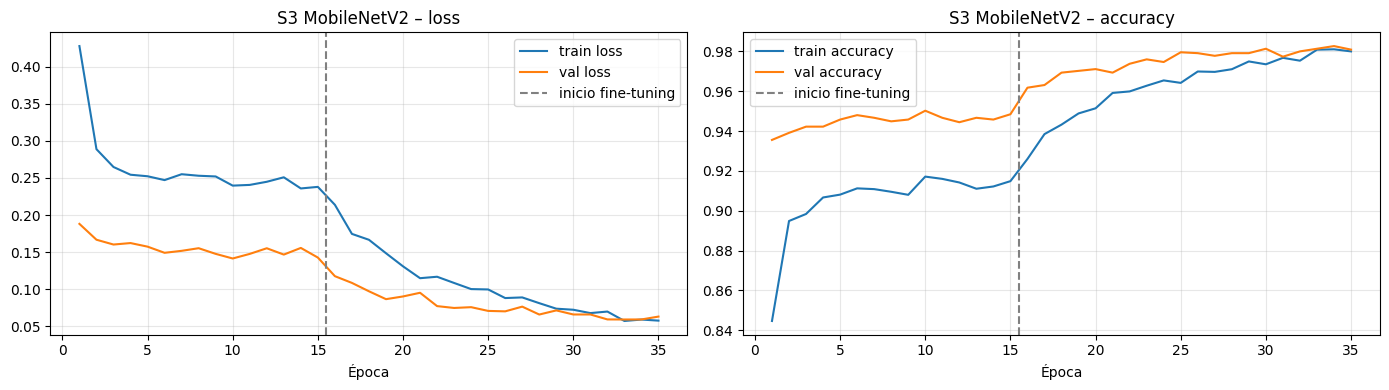

In [ ]:
historia_s3 = {k: hist_s3_fe.history[k] + hist_s3_ft.history[k]
               for k in ["loss", "val_loss", "accuracy", "val_accuracy"]}
inicio_ft = len(hist_s3_fe.history["loss"])
epocas = range(1, len(historia_s3["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, metrica in zip(axes, ["loss", "accuracy"]):
    ax.plot(epocas, historia_s3[metrica], label=f"train {metrica}")
    ax.plot(epocas, historia_s3[f"val_{metrica}"], label=f"val {metrica}")
    ax.axvline(inicio_ft + 0.5, color="gray", linestyle="--", label="inicio fine-tuning")
    ax.set_title(f"S3 MobileNetV2 – {metrica}")
    ax.set_xlabel("Época")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

### S3.5 Evaluación en el conjunto de test

El conjunto de test no se ha usado ni para entrenar ni para elegir hiperparámetros. Se calculan la *accuracy*, el F1 macro, el informe por clase y la matriz de confusión.

modelo           S3 MobileNetV2
val_acc_fase1          0.950222
val_acc                0.981333
test_acc               0.988889
test_f1_macro          0.988889
parametros              2266947
epocas                       35
tiempo_min             10.15322

              precision    recall  f1-score   support

        Shoe     0.9854    0.9893    0.9874       750
      Sandal     0.9868    0.9933    0.9900       750
        Boot     0.9946    0.9840    0.9893       750

    accuracy                         0.9889      2250
   macro avg     0.9889    0.9889    0.9889      2250
weighted avg     0.9889    0.9889    0.9889      2250



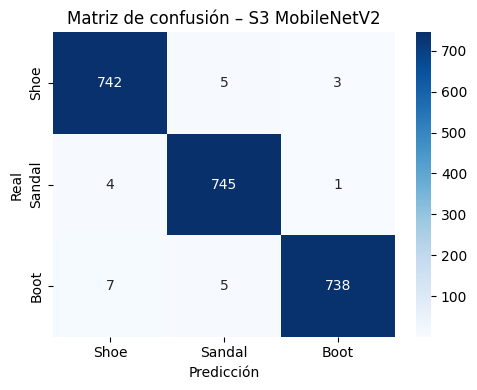

In [ ]:
y_test_s3 = np.concatenate([etiquetas.numpy() for _, etiquetas in test_dataset])
probs_s3 = modelo_s3.predict(test_dataset, verbose=0)
pred_s3 = probs_s3.argmax(axis=1)

val_loss_s3, val_acc_s3 = modelo_s3.evaluate(val_dataset, verbose=0)
test_acc_s3 = accuracy_score(y_test_s3, pred_s3)
test_f1_s3 = f1_score(y_test_s3, pred_s3, average="macro")

resultados_s3 = {
    "modelo": "S3 MobileNetV2",
    "val_acc_fase1": val_acc_fe,
    "val_acc": val_acc_s3,
    "test_acc": test_acc_s3,
    "test_f1_macro": test_f1_s3,
    "parametros": modelo_s3.count_params(),
    "epocas": len(historia_s3["loss"]),
    "tiempo_min": (tiempo_s3_fe + tiempo_s3_ft) / 60,
}
print(pd.Series(resultados_s3).to_string())
print()
print(classification_report(y_test_s3, pred_s3, target_names=NOMBRES_CLASES, digits=4))

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test_s3, pred_s3), annot=True, fmt="d", cmap="Blues",
            xticklabels=NOMBRES_CLASES, yticklabels=NOMBRES_CLASES, ax=ax)
ax.set_xlabel("Predicción")
ax.set_ylabel("Real")
ax.set_title("Matriz de confusión – S3 MobileNetV2")
plt.tight_layout()
plt.show()

### S3.6 Análisis de errores

Ejemplos del conjunto de test mal clasificados, con la clase real (R), la predicha (P) y la confianza del modelo.

Imágenes mal clasificadas: 25 de 2250


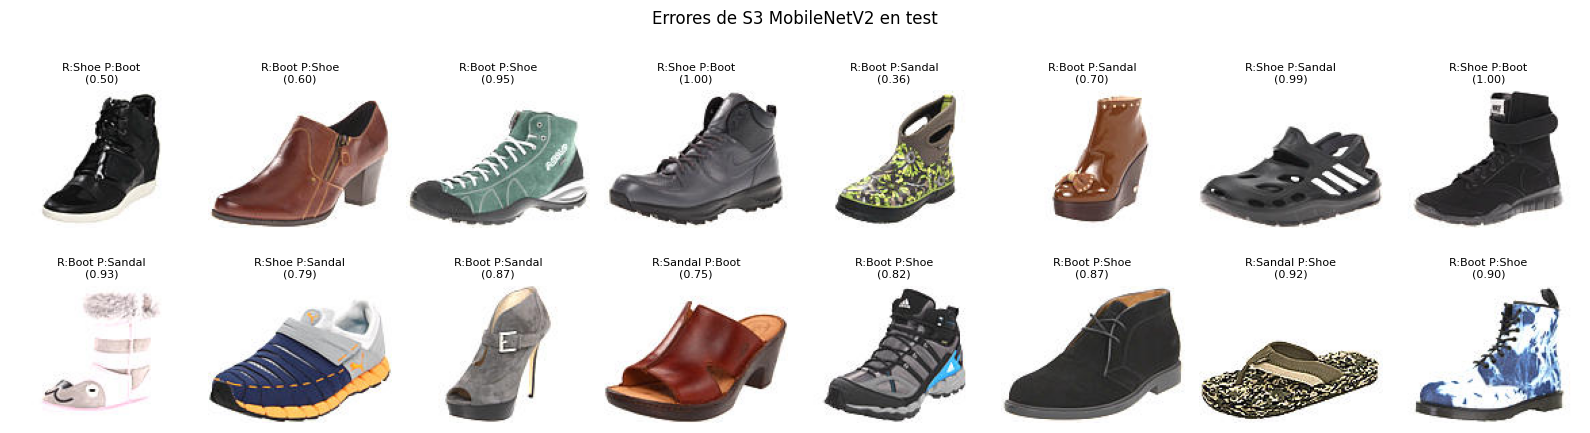

In [ ]:
errores_s3 = np.where(pred_s3 != y_test_s3)[0]
print(f"Imágenes mal clasificadas: {len(errores_s3)} de {len(y_test_s3)}")

n_mostrar = min(len(errores_s3), 16)
if n_mostrar:
    filas = int(np.ceil(n_mostrar / 8))
    fig, axes = plt.subplots(filas, 8, figsize=(16, 2.4 * filas), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, i in zip(axes.ravel(), errores_s3[:n_mostrar]):
        ax.imshow(Image.open(X_test[i]))
        ax.set_title(f"R:{NOMBRES_CLASES[y_test_s3[i]]} P:{NOMBRES_CLASES[pred_s3[i]]}\n({probs_s3[i].max():.2f})", fontsize=8)
    plt.suptitle("Errores de S3 MobileNetV2 en test")
    plt.tight_layout()
    plt.show()

### S3.7 Análisis de resultados

| Fase | Épocas (mejor) | Parámetros entrenables | *val accuracy* | Tiempo |
|---|---|---|---|---|
| 1. *Feature extraction* | 15 (10) | 6,403 | 0.9502 | 4.2 min |
| 2. *Fine-tuning* | 20 (18) | 1,669,763 | 0.9813 | 5.9 min |
| **Modelo final en test** | 35 en total | 2,266,947 en total | - | **10.2 min** |

**Resultado en test:** *accuracy* = **0.9889** y F1 macro = **0.9889**, con 25 errores de 2,250 imágenes. Es muy superior al rendimiento aleatorio (33.3%) y está equilibrado entre clases: el F1 por clase va de 0.987 (*Shoe*) a 0.990 (*Sandal*).

**Fase 1 (*feature extraction*):**
- Entrenando solo la cabeza (6,403 parámetros, el 0.3% del modelo), la red alcanza un 95% en validación desde las primeras épocas. Esto confirma que las características aprendidas en ImageNet ya separan bien los tres tipos de calzado.
- La *accuracy* de entrenamiento queda por debajo de la de validación porque el *data augmentation* y el *Dropout* solo actúan durante el entrenamiento. No indica subajuste.
- A partir de la época 6 la validación se estanca en torno al 94.5-95%. `ReduceLROnPlateau` reduce el *learning rate* y `EarlyStopping` detiene la fase en la época 15, restaurando los pesos de la época 10.

**Fase 2 (*fine-tuning*):**
- Al descongelar el último tramo de MobileNetV2 (13 de sus 104 capas con pesos) con *learning rate* 1e-5, la `val_loss` baja de 0.14 a 0.06. La *accuracy* de validación sube de 0.950 a 0.981, lo que reduce el error de validación de un 5.0% a un 1.9% (**-62%**).
- La mejora es progresiva y estable, sin los saltos propios de un *learning rate* demasiado alto.
- Al final de esta fase, las curvas de entrenamiento y validación prácticamente coinciden (0.98 en ambas). El modelo no sobreajusta, gracias a la combinación de *data augmentation*, *Dropout*, regularización L2, BN congeladas y *learning rate* bajo.
- Esto justifica empíricamente el uso del *fine-tuning*: adaptar las características de alto nivel al dominio del calzado aporta una mejora clara sobre usarlas tal cual.

**Matriz de confusión y errores:**
- La confusión más frecuente es ***Boot* → *Shoe*** (7 casos), seguida de *Shoe* → *Sandal* y *Boot* → *Sandal* (5 cada una). *Boot* es la clase con menor *recall* (0.984) pero con la mayor *precision* (0.995): el modelo es conservador al predecir "bota" y falla sobre todo con botines bajos.
- En la galería de errores predominan **casos frontera o con etiqueta discutible**:
  - zapatillas de caña alta etiquetadas como *Shoe* y predichas como *Boot* (algunas con confianza 1.00);
  - botines bajos y de tacón, y botas de agua cortas;
  - una sandalia cerrada tipo deportiva etiquetada como *Shoe*;
  - botines abiertos de tacón y zuecos.
- Varios errores tienen confianza baja (0.36-0.60), lo que indica que el modelo "duda" precisamente en las imágenes ambiguas. Con un 1.1% de error, buena parte del margen restante parece deberse a la propia ambigüedad del etiquetado más que a una limitación del modelo.

**Conclusión de S3:** MobileNetV2 con *transfer learning* + *fine-tuning* obtiene un **98.9% de *accuracy* y F1 macro en test** con solo 2.3 M de parámetros y unos 10 minutos de entrenamiento en GPU. Es una solución precisa, estable y muy eficiente. Su resultado servirá como referencia para compararla con DenseNet121 (S4) dentro de la Estrategia 2 y con las soluciones *from scratch* de la Estrategia 1.

## S4 - DenseNet121

DenseNet121 es una red preentrenada con ImageNet. En cada bloque denso, cada capa recibe las salidas de todas las capas anteriores del bloque, lo que permite reutilizar características. Su base tiene 7,037,504 parámetros. Se eligió para ver si una red más pesada que MobileNetV2 mejora la accuracy en este dataset.

Decisiones de diseño:
- Entrada: imágenes de 150x150 en el rango [0, 1], tomadas de train_dataset, val_dataset y test_dataset. Una capa Normalization aplica la media y la desviación estándar de ImageNet, que es la normalización con la que se entrenó DenseNet121.
- Data augmentation: se usa la capa común data_augmentation dentro del modelo, así que solo actúa en training.
- Cabeza de clasificación: GlobalAveragePooling2D, BatchNormalization, Dropout de 0.4 y Dense de 3 clases con softmax y L2 de 1e-4. Es la misma de S3, para que la diferencia venga de la red base.
- Callbacks: EarlyStopping sobre val_loss, restaurando los mejores pesos, y ReduceLROnPlateau.
- Fine-tuning: se descongela el último bloque denso (desde conv5_block1_0_bn) con learning rate de 1e-5. Las capas de Batch Normalization de la base siguen congeladas.
- Épocas: máximo 15 en la fase 1 y 20 en la fase 2, igual que en S3.

In [13]:
# Librerías de la sección S4
import time
import keras
from keras import layers, regularizers
import seaborn as sns
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

keras.utils.set_random_seed(42)

nombres_clases = sorted(clases_a_etiquetas, key=clases_a_etiquetas.get)
num_clases = len(nombres_clases)
tam_entrada = (*IMG_SIZE, 3)

s4_epocas_fe = 15                      # fase 1: feature extraction
s4_epocas_ft = 20                      # fase 2: fine-tuning
s4_capa_ft = "conv5_block1_0_bn"       # primera capa del último bloque denso

# Media y desviación estándar de ImageNet por canal (RGB), para imágenes en [0, 1]
media_imagenet = [0.485, 0.456, 0.406]
desviacion_imagenet = [0.229, 0.224, 0.225]

print("Clases:", dict(enumerate(nombres_clases)))
print("Tamaño de entrada:", tam_entrada)

Clases: {0: 'Shoe', 1: 'Sandal', 2: 'Boot'}
Tamaño de entrada: (150, 150, 3)


### S4.1 Construcción del modelo

In [14]:
def construir_s4_densenet121():
    base = keras.applications.DenseNet121(include_top=False, weights="imagenet", input_shape=tam_entrada)
    base.trainable = False

    entrada = keras.Input(shape=tam_entrada)
    x = data_augmentation(entrada)              # capa común definida en la sección de Data Augmentation
    x = layers.Normalization(mean=media_imagenet,
                             variance=[d ** 2 for d in desviacion_imagenet])(x)   # normalización de ImageNet
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.4)(x)
    salida = layers.Dense(num_clases, activation="softmax", kernel_regularizer=regularizers.L2(1e-4))(x)
    return keras.Model(entrada, salida, name="S4_DenseNet121"), base


def callbacks_s4(paciencia):
    return [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=paciencia, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7, verbose=1),
    ]


def contar_entrenables(modelo):
    return sum(int(np.prod(w.shape)) for w in modelo.trainable_weights)


modelo_s4, base_s4 = construir_s4_densenet121()
modelo_s4.summary()
print(f"Parámetros totales: {modelo_s4.count_params():,} | entrenables en la fase 1: {contar_entrenables(modelo_s4):,}")

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "S4_DenseNet121"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization (Normalization)   │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 4, 4, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1024)           │         4,096 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,075 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,044,675 (26.87 MB)

 Trainable params: 5,123 (20.01 KB)

 Non-trainable params: 7,039,552 (26.85 MB)

Parámetros totales: 7,044,675 | entrenables en la fase 1: 5,123


### S4.2 Fase 1: transfer learning (feature extraction)

Solo se entrena la cabeza de clasificación, con Adam y learning rate de 1e-3. El barajado de los lotes ya lo hace train_dataset en cada época, por eso se indica shuffle=False en fit.

In [15]:
modelo_s4.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])

inicio = time.time()
hist_s4_fe = modelo_s4.fit(train_dataset, validation_data=val_dataset, shuffle=False, epochs=s4_epocas_fe,
                           callbacks=callbacks_s4(paciencia=5), verbose=2)
tiempo_s4_fe = time.time() - inicio

val_loss_s4_fe, val_acc_s4_fe = modelo_s4.evaluate(val_dataset, verbose=0)
print(f"\nFase 1 completada en {tiempo_s4_fe / 60:.1f} min | validation accuracy = {val_acc_s4_fe:.4f}")

Epoch 1/15
329/329 - 61s - 187ms/step - accuracy: 0.8442 - loss: 0.3981 - val_accuracy: 0.9271 - val_loss: 0.1889 - learning_rate: 0.0010
Epoch 2/15
329/329 - 30s - 93ms/step - accuracy: 0.9045 - loss: 0.2530 - val_accuracy: 0.9400 - val_loss: 0.1518 - learning_rate: 0.0010
Epoch 3/15
329/329 - 31s - 94ms/step - accuracy: 0.9152 - loss: 0.2258 - val_accuracy: 0.9453 - val_loss: 0.1423 - learning_rate: 0.0010
Epoch 4/15
329/329 - 31s - 95ms/step - accuracy: 0.9216 - loss: 0.2162 - val_accuracy: 0.9511 - val_loss: 0.1305 - learning_rate: 0.0010
Epoch 5/15
329/329 - 31s - 95ms/step - accuracy: 0.9191 - loss: 0.2130 - val_accuracy: 0.9516 - val_loss: 0.1296 - learning_rate: 0.0010
Epoch 6/15
329/329 - 31s - 95ms/step - accuracy: 0.9238 - loss: 0.2045 - val_accuracy: 0.9551 - val_loss: 0.1216 - learning_rate: 0.0010
Epoch 7/15
329/329 - 31s - 94ms/step - accuracy: 0.9280 - loss: 0.2054 - val_accuracy: 0.9538 - val_loss: 0.1253 - learning_rate: 0.0010
Epoch 8/15
329/329 - 42s - 126ms/step - 

### S4.3 Fase 2: fine-tuning

Se descongela el último bloque denso de DenseNet121 (desde conv5_block1_0_bn), manteniendo congeladas sus capas de Batch Normalization, y se vuelve a entrenar con un learning rate de 1e-5.

In [16]:
base_s4.trainable = True
indice_ft = [capa.name for capa in base_s4.layers].index(s4_capa_ft)
for i, capa in enumerate(base_s4.layers):
    capa.trainable = i >= indice_ft and not isinstance(capa, layers.BatchNormalization)

capas_con_pesos = [capa for capa in base_s4.layers if capa.weights]
print(f"Capas de la base con pesos entrenables: {sum(capa.trainable for capa in capas_con_pesos)} de {len(capas_con_pesos)}")

modelo_s4.compile(optimizer=keras.optimizers.Adam(1e-5),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
print(f"Parámetros entrenables en la fase 2: {contar_entrenables(modelo_s4):,}")

inicio = time.time()
hist_s4_ft = modelo_s4.fit(train_dataset, validation_data=val_dataset, shuffle=False, epochs=s4_epocas_ft,
                           callbacks=callbacks_s4(paciencia=6), verbose=2)
tiempo_s4_ft = time.time() - inicio
print(f"\nFase 2 completada en {tiempo_s4_ft / 60:.1f} min")

Capas de la base con pesos entrenables: 32 de 241
Parámetros entrenables en la fase 2: 2,135,043
Epoch 1/20
329/329 - 57s - 173ms/step - accuracy: 0.9343 - loss: 0.1815 - val_accuracy: 0.9631 - val_loss: 0.1086 - learning_rate: 1.0000e-05
Epoch 2/20
329/329 - 34s - 105ms/step - accuracy: 0.9391 - loss: 0.1706 - val_accuracy: 0.9649 - val_loss: 0.1012 - learning_rate: 1.0000e-05
Epoch 3/20
329/329 - 41s - 126ms/step - accuracy: 0.9470 - loss: 0.1550 - val_accuracy: 0.9671 - val_loss: 0.0947 - learning_rate: 1.0000e-05
Epoch 4/20
329/329 - 34s - 105ms/step - accuracy: 0.9502 - loss: 0.1412 - val_accuracy: 0.9684 - val_loss: 0.0912 - learning_rate: 1.0000e-05
Epoch 5/20
329/329 - 35s - 105ms/step - accuracy: 0.9478 - loss: 0.1448 - val_accuracy: 0.9689 - val_loss: 0.0889 - learning_rate: 1.0000e-05
Epoch 6/20
329/329 - 35s - 106ms/step - accuracy: 0.9543 - loss: 0.1300 - val_accuracy: 0.9720 - val_loss: 0.0862 - learning_rate: 1.0000e-05
Epoch 7/20
329/329 - 35s - 107ms/step - accuracy: 0

### S4.4 Monitorización del entrenamiento

Curvas de loss y accuracy de training y validation de las dos fases. La línea punteada marca el inicio del fine-tuning.

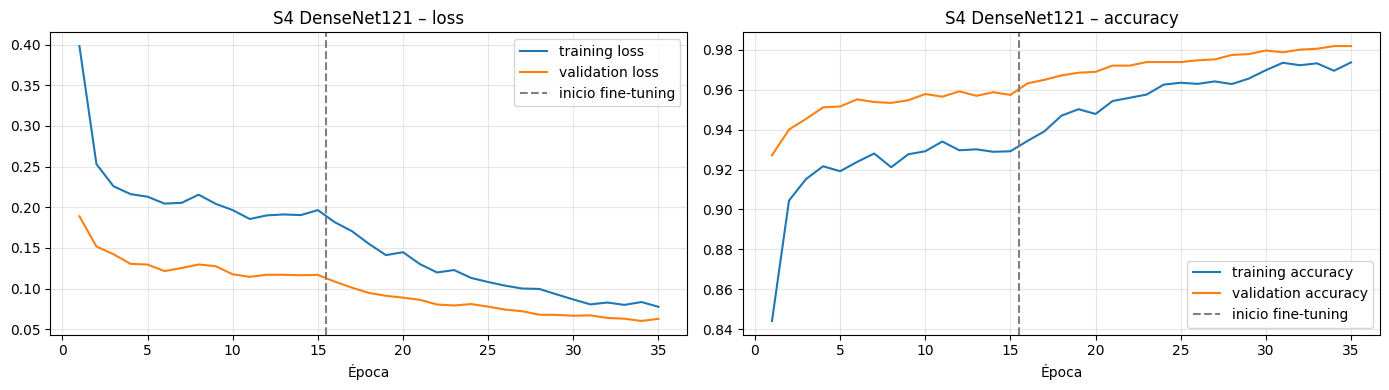

In [17]:
historia_s4 = {k: hist_s4_fe.history[k] + hist_s4_ft.history[k]
               for k in ["loss", "val_loss", "accuracy", "val_accuracy"]}
inicio_ft_s4 = len(hist_s4_fe.history["loss"])
epocas_s4 = range(1, len(historia_s4["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, metrica in zip(axes, ["loss", "accuracy"]):
    ax.plot(epocas_s4, historia_s4[metrica], label=f"training {metrica}")
    ax.plot(epocas_s4, historia_s4[f"val_{metrica}"], label=f"validation {metrica}")
    ax.axvline(inicio_ft_s4 + 0.5, color="gray", linestyle="--", label="inicio fine-tuning")
    ax.set_title(f"S4 DenseNet121 – {metrica}")
    ax.set_xlabel("Época")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

### S4.5 Evaluación en el conjunto de test

El conjunto de test no se usó para entrenar ni para elegir hiperparámetros. Se calculan la accuracy, el F1 macro, el reporte por clase y la matriz de confusión. Los resultados se guardan con las mismas claves que en S3 para poder comparar los modelos.

modelo           S4 DenseNet121
val_acc_fase1          0.956444
val_acc                0.981778
test_acc               0.982667
test_f1_macro          0.982657
parametros              7044675
epocas                       35
tiempo_min            21.005043

              precision    recall  f1-score   support

        Shoe     0.9839    0.9760    0.9799       750
      Sandal     0.9789    0.9920    0.9854       750
        Boot     0.9853    0.9800    0.9826       750

    accuracy                         0.9827      2250
   macro avg     0.9827    0.9827    0.9827      2250
weighted avg     0.9827    0.9827    0.9827      2250



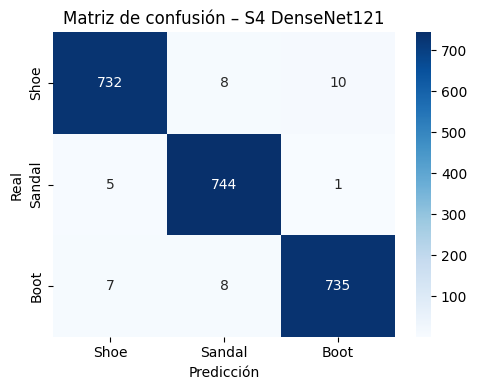

In [18]:
y_test_s4 = np.concatenate([etiquetas.numpy() for _, etiquetas in test_dataset])
probs_s4 = modelo_s4.predict(test_dataset, verbose=0)
y_pred_s4 = probs_s4.argmax(axis=1)

val_loss_s4, val_acc_s4 = modelo_s4.evaluate(val_dataset, verbose=0)
test_acc_s4 = accuracy_score(y_test_s4, y_pred_s4)
test_f1_s4 = f1_score(y_test_s4, y_pred_s4, average="macro")

resultados_s4 = {
    "modelo": "S4 DenseNet121",
    "val_acc_fase1": val_acc_s4_fe,
    "val_acc": val_acc_s4,
    "test_acc": test_acc_s4,
    "test_f1_macro": test_f1_s4,
    "parametros": modelo_s4.count_params(),
    "epocas": len(historia_s4["loss"]),
    "tiempo_min": (tiempo_s4_fe + tiempo_s4_ft) / 60,
}
print(pd.Series(resultados_s4).to_string())
print()
print(classification_report(y_test_s4, y_pred_s4, target_names=nombres_clases, digits=4))

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test_s4, y_pred_s4), annot=True, fmt="d", cmap="Blues",
            xticklabels=nombres_clases, yticklabels=nombres_clases, ax=ax)
ax.set_xlabel("Predicción")
ax.set_ylabel("Real")
ax.set_title("Matriz de confusión – S4 DenseNet121")
plt.tight_layout()
plt.show()

### S4.6 Análisis de errores

Ejemplos del conjunto de test mal clasificados, con la clase real (R), la predicha (P) y la confianza del modelo.

Imágenes mal clasificadas: 39 de 2250


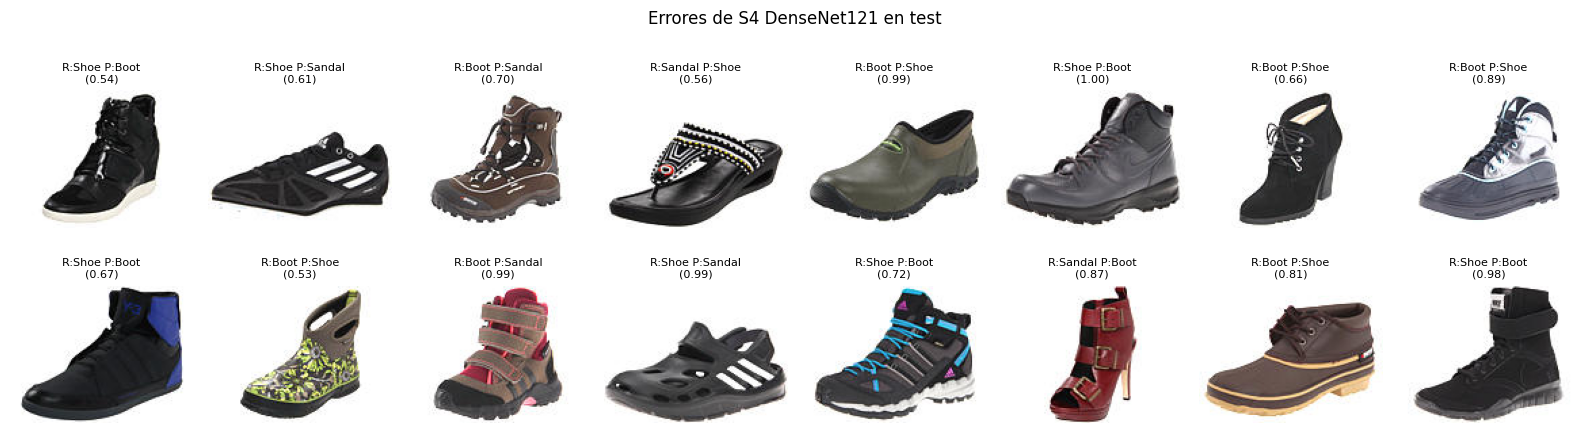

In [19]:
errores_s4 = np.where(y_pred_s4 != y_test_s4)[0]
print(f"Imágenes mal clasificadas: {len(errores_s4)} de {len(y_test_s4)}")

n_mostrar = min(len(errores_s4), 16)
if n_mostrar:
    filas = int(np.ceil(n_mostrar / 8))
    fig, axes = plt.subplots(filas, 8, figsize=(16, 2.4 * filas), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, i in zip(axes.ravel(), errores_s4[:n_mostrar]):
        ax.imshow(Image.open(X_test[i]))
        ax.set_title(f"R:{nombres_clases[y_test_s4[i]]} P:{nombres_clases[y_pred_s4[i]]}\n({probs_s4[i].max():.2f})", fontsize=8)
    plt.suptitle("Errores de S4 DenseNet121 en test")
    plt.tight_layout()
    plt.show()

### S4.7 Análisis de resultados

| Fase | Épocas (mejor) | Parámetros entrenables | Validation accuracy | Tiempo |
|---|---|---|---|---|
| 1. Feature extraction | 15 (11) | 5,123 | 0.9564 | 8.8 min |
| 2. Fine-tuning | 20 (19) | 2,135,043 | 0.9818 | 12.2 min |
| Modelo final en test | 35 en total | 7,044,675 en total | - | 21.0 min |

Resultado en test: accuracy de 0.9827 y F1 macro de 0.9827, con 39 errores de 2,250 imágenes. Las tres clases tienen un F1 parecido, entre 0.9799 y 0.9854.

- Fase 1: entrenando solo la cabeza, la validation accuracy llega a 0.9564. Las características de ImageNet ya separan bien los tres tipos de calzado.
- Fase 2: el fine-tuning baja el error de validation de 4.4% a 1.8%. La mejor época fue la 19 de 20, así que valdría la pena probar con más épocas.
- Sobreajuste: no se ve. Al final la training accuracy (0.9736) y la de validation (0.9818) están cerca. La de training queda abajo porque el data augmentation y el Dropout solo actúan en training.
- Errores: la confusión más común es Shoe predicho como Boot (10 casos). Varias son tenis de caña alta, y al menos cinco de las imágenes mal clasificadas también aparecen en los errores de S3. Que las dos redes fallen en las mismas imágenes apunta a casos ambiguos o con etiqueta discutible, más que a un problema de DenseNet121.

#### Comparación con S3 (MobileNetV2)

| | S3 MobileNetV2 | S4 DenseNet121 |
|---|---|---|
| Validation accuracy final | 0.9813 | 0.9818 |
| Test accuracy | 0.9889 | 0.9827 |
| Test F1 macro | 0.9889 | 0.9827 |
| Errores en test | 25 | 39 |
| Parámetros | 2,266,947 | 7,044,675 |
| Tiempo de entrenamiento | 10.2 min | 21.0 min |

MobileNetV2 tiene mejor accuracy en test (0.9889 contra 0.9827) con un tercio de los parámetros y la mitad del tiempo de entrenamiento. En validation los dos modelos terminan casi igual (0.9813 y 0.9818), así que la diferencia aparece en test y equivale a 14 imágenes de 2,250. Con estos resultados, usar una red más pesada no mejora la accuracy en test. Además, las dos redes fallan en varias de las mismas imágenes, lo que apunta a que parte del error viene de casos ambiguos más que de la arquitectura.

## Ejemplo de generación de documento PDF a partir del Colab Notebook (fichero ".ipynb")

In [ ]:
# Ejecutando los siguientes comandos en la última celda del Colab Notebook se convierte de ".ipynb" a PDF
# En caso de querer ocultar la salida de una celda puesto que no tenga relevancia se debe insertar
# el comando %%capture al inicio de la misma. Véase la celda que contiene !ls test en este Notebook.

In [ ]:
name_IPYNB_file = '07MIAR_Proyecto_Programacion.ipynb'
get_ipython().system(
        "apt update >> /dev/null && apt install texlive-xetex texlive-fonts-recommended texlive-generic-recommended >> /dev/null"
    )
get_ipython().system(
            "jupyter nbconvert --output-dir='$BASE_FOLDER' '$BASE_FOLDER''$name_IPYNB_file' --to pdf"
        )



W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)


E: Unable to locate package texlive-generic-recommended
[NbConvertApp] WARNING | pattern '$BASE_FOLDER$name_IPYNB_file' matched no files
[NbConvertApp] Making directory $BASE_FOLDER
This application is used to convert notebook files (*.ipynb)
        to various other formats.


Options
The options below are convenience aliases to configurable class-options,
as listed in the "Equivalent to" description-line of the aliases.
To see all configurable class-options for some <cmd>, use:
    <cmd> --help-all

--debug
    set log level to logging.DEBUG (maximize logging output)
    Equivalent to: [--Application.log_level=10]
--show-config
    Show the application's configuration (human-readable format)
    Equivalent to: [--Application.show_config=True]
--show-config-json
    Show the application's config